### Exercise 1.4

In [89]:
import random
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

According to the problem statement, first we will make a random line in the plane and draw it.

In [90]:
slop = random.randint(-10, 10)
y_intercept = random.randint(-10, 10)

In [91]:
print(f"slop: {slop}")
print(f"y intercept: {y_intercept}")
print(f"x2 = {slop} * x1 + {y_intercept}")

slop: -7
y intercept: 1
x2 = -7 * x1 + 1


Then we will make our dataset, random dots that based on target line we will seperate them to +1 and -1.

In [92]:
dataset = np.random.randint(-100, 100, size=[20, 2])
dataset

array([[ 66,  91],
       [-73, -27],
       [  1, -85],
       [ 26,  88],
       [-42, -17],
       [-19,  87],
       [ 85, -77],
       [-51,  64],
       [ -3, -17],
       [-35,  98],
       [ 90, -21],
       [ 31,  47],
       [-98, -23],
       [-33,  17],
       [ 26, -99],
       [ 87,  38],
       [-66, -90],
       [-85,  22],
       [ 69, -72],
       [ -5,   2]])

In this part we will evaluate dots with comparing them with target line and label them.    
then plot them.

In [93]:
target = np.where(dataset[:, 1] >= slop * dataset[:, 0] + y_intercept, 1, -1)
target

array([ 1, -1, -1,  1, -1, -1,  1, -1, -1, -1,  1,  1, -1, -1,  1,  1, -1,
       -1,  1, -1])

In [ ]:
plus_data = np.where(target == 1)
plus_data

(array([ 0,  3,  6, 10, 11, 14, 15, 18]),)

In [95]:
minus_data = np.where(target == -1)
minus_data

(array([ 1,  2,  4,  5,  7,  8,  9, 12, 13, 16, 17, 19]),)

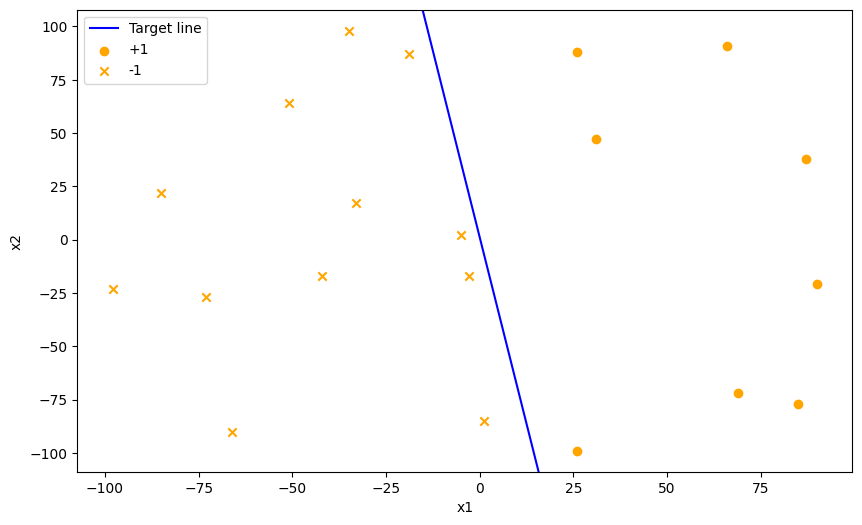

In [102]:
plt.figure(figsize=(10, 6))
plt.xlabel("x1")
plt.ylabel("x2")
plt.axline(slope=slop, xy1=(0, y_intercept), label="Target line", color="blue")
plt.scatter(dataset[plus_data, 0], dataset[plus_data, 1], color="orange", marker="o", label="+1")
plt.scatter(dataset[minus_data, 0], dataset[minus_data, 1], color="orange", marker="x", label="-1")
plt.legend()
plt.show()

Build weight array with w0, w1, w2.

In [97]:
w = np.array([0, 0, 0], dtype=np.int64)

In [98]:
print(f"w: {w}")

w: [0 0 0]


First we will add 1 as x0 to our dataset and call it X, because the equation is like this:    

`w2x2 + w1x1 + w0 = 0`    

w0 is for bias that our line don't just go through (0, 0).

In [99]:
X = np.concat([np.ones((len(dataset), 1), dtype=np.int64), dataset], axis=1)

Then we will do the training part:

In [100]:
while True:
    predict = np.transpose(np.where(np.dot(X, w) >= 0, 1, -1)).reshape(len(target))
    missclassified = np.where(target != predict)[0]
    print(f"Index of missclassified data: {missclassified}")
    if (len(list(missclassified)) == 0):
        break
    i = missclassified[0]
    w += target[i] * X[i]

Index of missclassified data: [ 1  2  4  5  7  8  9 12 13 16 17 19]
Index of missclassified data: [ 5  9 14]
Index of missclassified data: [2 3 8]
Index of missclassified data: [ 5 14]
Index of missclassified data: [2 3 8]
Index of missclassified data: []


Plot the target line and PLA line:

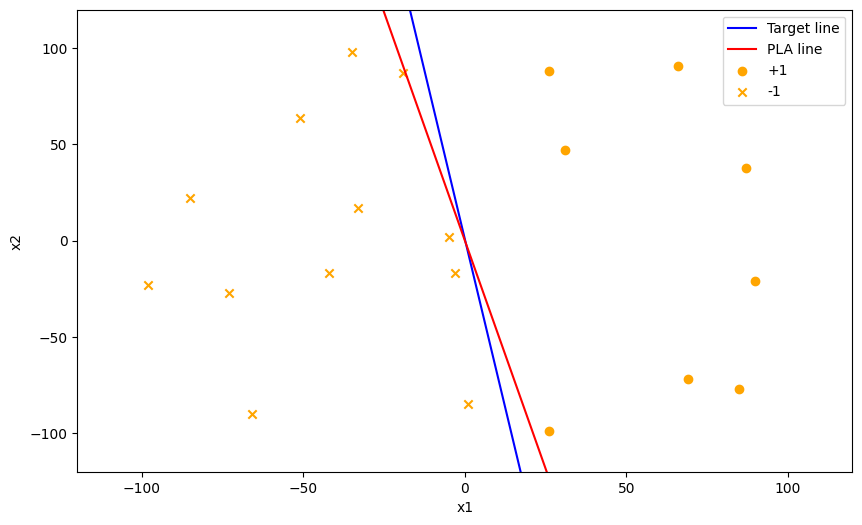

In [101]:
plt.figure(figsize=(10, 6))
plt.xlabel("x1")
plt.ylabel("x2")
plt.axline(slope=slop, xy1=(0, y_intercept), color = "blue", label="Target line")
plt.axline(xy1=(0, -w[0] / w[2]),slope=-w[1] / w[2], color="red", label="PLA line")
plt.scatter(dataset[plus_data, 0], dataset[plus_data, 1], color="orange", marker="o", label="+1")
plt.scatter(dataset[minus_data, 0], dataset[minus_data, 1], color="orange", marker="x", label="-1")
plt.xlim(-120, 120)
plt.ylim(-120, 120)
plt.legend()
plt.show()